# Simple Linear Regression

Fit and interpret a one-predictor regression of salary on training hours.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

from pathlib import Path


def find_repo_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise RuntimeError("Could not find repository root")


ROOT = find_repo_root()
DATA = ROOT / "data"

In [2]:
df = pd.read_csv(DATA / "career_outcomes.csv")
df.head()

,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
0,1.2,12,38.2,technology,0,4.8,60.2,0
1,5.1,16,20.7,technology,1,4.0,66.5,1
2,8.5,14,60.5,retail,0,8.2,76.5,1
3,9.7,16,38.7,finance,0,0.7,84.7,0
4,2.5,16,60.7,public,0,4.7,67.6,0


In [3]:
df["training_hours"].describe()

count    240.000000
mean      39.675417
std       16.086017
min        0.000000
25%       28.950000
50%       39.300000
75%       49.825000
max       90.000000
Name: training_hours, dtype: float64

So the data covers 0 to 90 hours, and most workers are around 40.

## Analytic question

- Outcome: Salary (salary_k_eur), measured in thousand euros.
- Predictor: Training hours (training_hours), measured in hours.
- Expected direction: Positive. I expect salary to increase with training hours, because training builds skills that employers may pay more for.
- Omitted variable: AI tool use (ai_tool_use). Workers who use AI tools more tend to train more and also earn more, so it could make training look more important for salary than it really is.

The idea in one sentence:
We use training hours (X) to explain salary (Y), we expect a positive relationship, and AI tool use could be confusing the picture.



[Text(0.5, 1.0, 'Salary and training hours'),
 Text(0.5, 0, 'Training hours'),
 Text(0, 0.5, 'Salary, thousand EUR')]

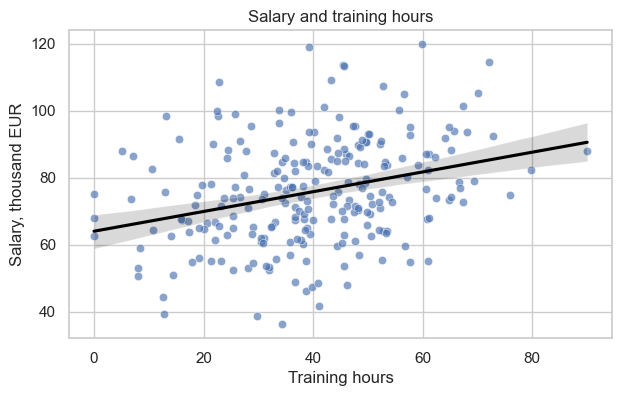

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="training_hours", y="salary_k_eur", alpha=0.65, ax=ax)
sns.regplot(data=df, x="training_hours", y="salary_k_eur", scatter=False, color="black", ax=ax)
ax.set(title="Salary and training hours", xlabel="Training hours", ylabel="Salary, thousand EUR")

In [5]:
model = smf.ols("salary_k_eur ~ training_hours", data=df).fit(cov_type="HC3")  # robust standard errors
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     26.80
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           4.80e-07
Time:                        20:10:29   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.511     25.

###### These are the before and after numbers
###### print(model.bse)
###### print(model.conf_int())

- Before (default SE): SE = 0.060, 95% CI [0.176, 0.414]
- After (HC3): SE = 0.057, 95% CI [0.183, 0.407]

HC3 doesnt change the slope and the CI changed only a little, from [0.176, 0.414] to [0.183, 0.407]. Both are clearly above zero, so the conclusion stays the same: more training is associated with higher salary. 

In [6]:
intercept = model.params["Intercept"]
slope = model.params["training_hours"]
training_sd = df["training_hours"].std()
print(f"Predicted salary with no training: {intercept:.1f} thousand EUR")
print(f"Estimated salary change per additional training hour: {slope:.2f} thousand EUR")

Predicted salary with no training: 64.0 thousand EUR
Estimated salary change per additional training hour: 0.30 thousand EUR


In [7]:
# Self-Check: one extra hour = slope
print(model.predict(pd.DataFrame({"training_hours": [40, 41]})))
print(slope)

0    75.775371
1    76.070481
dtype: float64
0.2951102810348345


- Salary at 40 hours = 75.775
- Salary at 41 hours = 76.070
- Difference = 76.070 − 75.775 = 0.295

So one extra hour of training is associated with about 0.295 thousand EUR (≈ €295) higher salary. The original per-hour calculation was wrong (it multiplied the slope by the SD of training hours, about 16 hours); now fixed.

In [8]:
print((df["training_hours"] >= 80).sum())
print((df["training_hours"] <= 10).sum())

1
9


In [9]:
new_workers = pd.DataFrame({"training_hours": [10, 40, 80]})
predictions = model.get_prediction(new_workers).summary_frame(alpha=0.05)
new_workers.join(predictions[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]])

,training_hours,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,10,66.922063,63.008487,70.835639,37.315123,96.529003
1,40,75.775371,73.875674,77.675069,46.366807,105.183936
2,80,87.579782,82.789028,92.370537,57.844179,117.315386


 A regression line is only well supported where there's data. At 40 hours there are many workers. At 80+ there's only 1, so the model is mostly extending the straight line out beyond where the data is and assuming it stays straight.

The 10-hour prediction has few workers nearby (9), so it's also less reliable than the one at 40.

Only 3 workers have 0 training hours, so the "predicted salary with no training" (the intercept, 64.0 thousand EUR) is also uncertain.

Looking and comparing these results with the scatterplot above we can conclude that the original cell was misleading. It said "predict salaries for new workers" but showed the narrow interval for the average. That makes the predictions look much more precise than they are.

[Text(0.5, 1.0, 'Residuals versus fitted values'),
 Text(0.5, 0, 'Fitted salary'),
 Text(0, 0.5, 'Residual')]

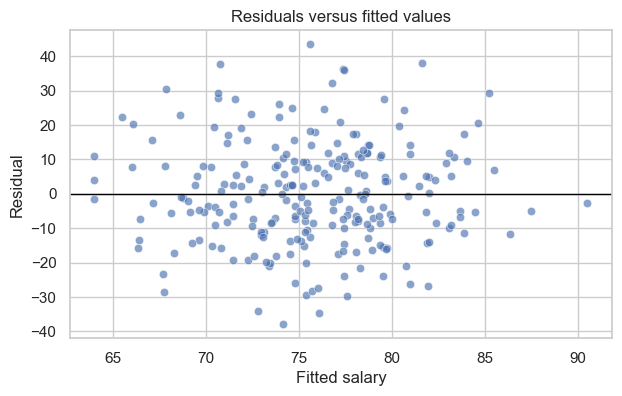

In [10]:
diagnostics = df.assign(fitted=model.fittedvalues, residual=model.resid)
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=diagnostics, x="fitted", y="residual", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Residuals versus fitted values", xlabel="Fitted salary", ylabel="Residual")

The residuals are spread randomly around the 0 line, with no clear curve or funnel shape: the spread is about the same for low and high fitted salaries. So a straight line seems reasonable here. The residuals are large (often ±15 thousand EUR or more), which matches the low R² (0.09): training hours explain only a small part of salary differences.

In [11]:
df.select_dtypes("number").corr().round(2)

,experience_years,education_years,training_hours,remote,ai_tool_use,salary_k_eur,promoted
experience_years,1.00,0.10,-0.07,0.01,0.00,0.57,0.31
education_years,0.10,1.00,0.02,0.06,-0.03,0.30,0.11
training_hours,-0.07,0.02,1.00,-0.04,0.62,0.30,0.33
remote,0.01,0.06,-0.04,1.00,0.14,0.15,0.12
ai_tool_use,0.00,-0.03,0.62,0.14,1.00,0.40,0.41
salary_k_eur,0.57,0.30,0.30,0.15,0.40,1.00,0.37
promoted,0.31,0.11,0.33,0.12,0.41,0.37,1.00


In [12]:
check = smf.ols("salary_k_eur ~ training_hours + ai_tool_use", data=df).fit(cov_type="HC3")
print(check.params)

Intercept         56.695260
training_hours     0.088894
ai_tool_use        2.401773
dtype: float64


Once we compare workers with the same AI tool use, one extra hour of training goes with only about €89 higher salary, not €295. A large part of the original 0.295 may be due to AI tool use: people who use AI tools more both train more and earn more.

## Interpretation

State the slope as an association, with units, and name one omitted variable that could confound it.

1. Main result: In the simple regression, one extra training hour is associated with about 0.30 thousand EUR (≈ €300) higher salary (95% CI 0.18 to 0.41 thousand EUR, about €183 to €407).
2. Association, not cause: This doesn't show training causes higher salary.
3. Confounder: ai_tool_use is linked to both training and salary. Among workers with the same AI tool use, the slope falls to about 0.089 thousand EUR (≈ €89).
4. Conclusion: So a large part of the simple slope maybe due to reflect of AI tool use rather than training itself.
